<a href="https://colab.research.google.com/github/maya300/Introduction_machine_learning/blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [5]:
cd gdrive/MyDrive/Machine_learning/Colab_Notebooks/

/content/gdrive/MyDrive/Machine_learning/Colab_Notebooks


## **Part I: Decision Stump By Hand**

In [6]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
file = "ATLAS_higgs_train.csv"
df = pd.read_csv(file)

In [8]:
print(df.head)

<bound method NDFrame.head of           Z1mass     Z2mass    detajj      massjj  l1pdgid     l1eta  \
0      68.515258  57.174385  4.283580  556.406882      -11  0.490221   
1      84.330551  25.551337  1.101106  266.768190      -11  1.291437   
2      90.902327  30.404745  2.394863  211.879331      -13  0.702544   
3      91.129112  26.609989  1.040268   56.235126      -11 -2.450392   
4      87.525977  32.304742  3.674720  351.241850       11 -1.303559   
...          ...        ...       ...         ...      ...       ...   
34995  80.639991  38.458791  0.139980   60.332091      -11  0.580589   
34996  95.477813   6.744652  4.084168  321.179218       13 -1.340675   
34997  89.303531  19.757941  0.471683   32.555787       11  0.410672   
34998  72.916616  37.974027  0.042897  122.989028      -11 -0.100711   
34999  43.953007  25.180254  0.768607   50.266907       11  0.880933   

          l1phi        l1pt  l2pdgid     l2eta  ...       l2pt  l3pdgid  \
0     -2.302279   68.776711   

In [9]:
#How many events does the file contain?
print("The file contain {} events".format(len(df)))

The file contain 35000 events


In [10]:
#How many events of each process (VBF and ggF) does the file contain?
ev_ggf, ev_vbf = 0,0
for n in range(len(df)):
  if df.loc[n, 'sample'] == -1:
    ev_ggf += 1
  else:
    ev_vbf += 1

print("There are {} events of 'VBF' and {} events of 'ggF' ".format(ev_ggf,ev_vbf))

There are 17500 events of 'VBF' and 17500 events of 'ggF' 


**1.1.2 Visualize the Training Data**

In [11]:
# Variables of interest
XNAME = 'detajj'; XLABEL = r'$|\Delta\eta_{jj}|$'
YNAME = 'massjj'; YLABEL = r'$m_{jj}$ (GeV)'

inputs = [XNAME, YNAME]

# Binning ranges
XBINS, XMIN, XMAX, XSTEP = 5, 0, 5, 1
YBINS, YMIN, YMAX, YSTEP = 5, 0, 1000, 200

# Split training data into signal and background
sig = df.loc[df['sample'] == 1,  inputs]
bkg = df.loc[df['sample'] == -1, inputs]

In [12]:
print(len(sig), len(bkg), len(sig) + len(bkg) == len(df))
print(sig.head())

17500 17500 True
     detajj      massjj
0  4.283580  556.406882
3  1.040268   56.235126
4  3.674720  351.241850
5  0.265865   23.380998
6  0.143978   35.743186


In [13]:
FONTSIZE = 16
params = {
         'axes.labelsize': FONTSIZE,
         'axes.titlesize': FONTSIZE,
         'xtick.labelsize':FONTSIZE,
         'ytick.labelsize':FONTSIZE,
         'legend.fontsize':FONTSIZE}
plt.rcParams.update(params)

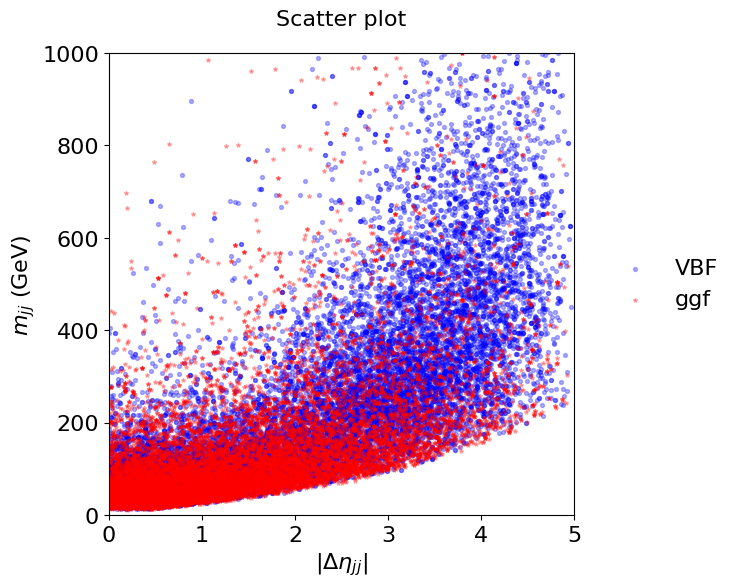

In [14]:
def plot_scatter(sig, bkg,
              xname=XNAME, xlabel=XLABEL, xmin=XMIN, xmax=XMAX, xstep=XSTEP,
              yname=YNAME, ylabel=YLABEL, ymin=YMIN, ymax=YMAX, ystep=YSTEP,
              fgsize=(6, 6), ftsize=FONTSIZE, alpha=0.3, title="Scatter plot"):

  fig, ax = plt.subplots(figsize=fgsize)

  # Annotate x-axis
  ax.set_xlim(xmin, xmax)
  ax.set_xlabel(xlabel)
  ax.set_xticks(np.arange(xmin, xmax+xstep, xstep))

  # Annotate y-axis
  ax.set_ylim(ymin, ymax)
  ax.set_ylabel(ylabel)
  ax.set_yticks(np.arange(ymin, ymax+ystep, ystep))

  # Scatter signal and background:
  ax.scatter(sig[xname], sig[yname], marker='o', s=8, c='b', alpha=alpha, label='VBF')
  ax.scatter(bkg[xname], bkg[yname], marker='*', s=8, c='r', alpha=alpha, label='ggf')

  # Legend and plot:
  ax.legend(fontsize=ftsize, bbox_to_anchor=(1.04, 0.5), loc="center left", frameon=False)
  ax.set_title(title, pad=20)
  plt.show()


plot_scatter(sig, bkg)


**1.1.3 Prepare Dataset (Features & Labels)**

In [15]:
# Extract detajj & massjj and convert to NumPy
X_train = df[inputs].to_numpy()

y_train = df['sample'].to_numpy()

print(len(X_train), len(y_train))


35000 35000


**1.2 Compute the Gini Index**

$G_{i} = 1 - \sum_{k=1}^(N_{classes}) (\dfrac{N_{k,i}}{N_{i}})^{2}$

In [16]:
def get_gini_index(y, classes):
    """
    y       : NumPy array of labels in the node
    classes : list of possible class values (e.g., [-1, 1])
    """
    G0 = 0
    if len(y) == 0:
      return 0
    for k in classes:
      j = y[y == k]
      G0 += (len(j) / len(y))**2

    return 1-G0

**Tests**

In [17]:
get_gini_index(y_train, [1, -1])


0.5

In [18]:
get_gini_index(y_train, [-1, -2])

0.75

**1.3 Compute the Cost Function**

In [19]:
def get_cost(n_left, gini_left, n_right, gini_right):
    """
        n_total is the total number of elements in the plot.
    """

    n_total = n_left + n_right
    J = (n_left * gini_left)/n_total + (n_right * gini_right)/n_total

    return J


**1.4 Decision Stump: Core of the Action**

In [20]:
def get_threshold_min_cost(feature_values, y, classes, precision=0.01):
    """
    Find the threshold that minimizes the weighted Gini index.

    Parameters
    ----------
    ...

    Returns
    -------
    ...

    """
    #Calculate the step
    min = feature_values.min()
    max = feature_values.max()
    step = precision * (max - min)

    #Calculate all the costs
    J_cost = []
    t_cost = []
    for t in np.arange(min+step, max, step):
      values_left = y[feature_values < t]
      values_right = y[feature_values > t]

      if len(values_left) == 0 or len(values_right) == 0:
        continue

      n_left = len(values_left)
      gini_left = get_gini_index(values_left, classes)
      n_right = len(values_right)
      gini_right = get_gini_index(values_right, classes)

      #The cost
      j = get_cost(n_left, gini_left, n_right, gini_right)
      J_cost.append(j)
      t_cost.append(t)

    #The minimum cost
    Jmin = J_cost[0]
    for i in J_cost:
        if i < Jmin:
          Jmin = i

    ide = J_cost.index(Jmin)
    tmin = float(t_cost[ide])

    return Jmin,tmin

**1.5 What Is the Best Split?**

In [21]:
classes = [1, -1]

cost_massjj = get_threshold_min_cost(X_train[:, 1], y_train, classes, precision=0.01)
cost_massjj

(0.45646532749626645, 211.367204057029)

In [22]:
cost_detajj = get_threshold_min_cost(X_train[:, 0], y_train, classes, precision=0.01)
cost_detajj

(0.46602510415670934, 2.5428917470574377)

In [23]:
if cost_detajj[0] < cost_massjj[0]:
    best_feature, best_t = XNAME, cost_detajj[1]
else:
    best_feature, best_t = YNAME, cost_massjj[1]
print(f"Final stump: cut on {best_feature} at {best_t:.3f}")

Final stump: cut on massjj at 211.367


**1.6 Plot the Cut**

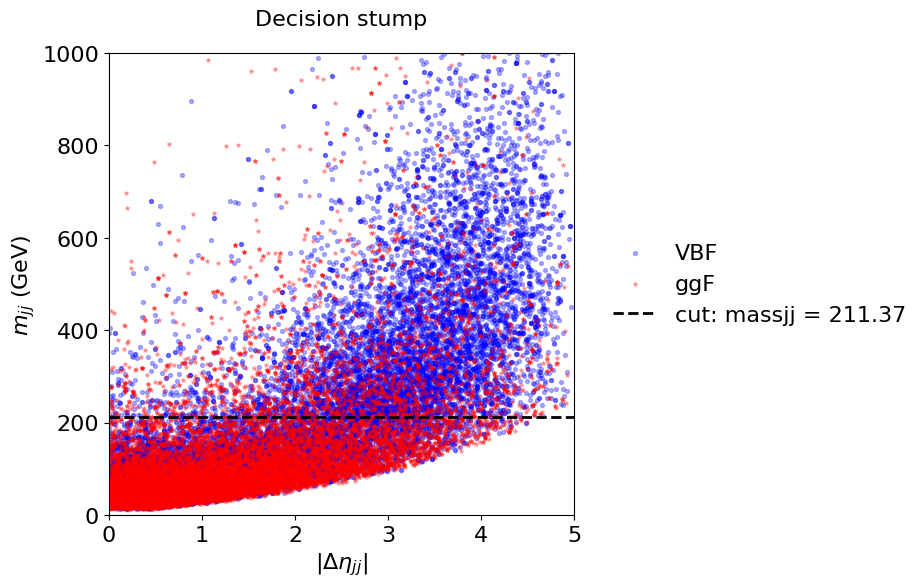

In [24]:
def plot_scatter(sig, bkg,
                 xname=XNAME, xlabel=XLABEL, xmin=XMIN, xmax=XMAX, xstep=XSTEP,
                 yname=YNAME, ylabel=YLABEL, ymin=YMIN, ymax=YMAX, ystep=YSTEP,
                 fgsize=(6, 6), ftsize=FONTSIZE, alpha=0.3, title="Scatter plot",
                 cut_feature=None, cut_value=None):          # new arguments

    fig, ax = plt.subplots(figsize=fgsize)

    ax.set_xlim(xmin, xmax)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(xmin, xmax + xstep, xstep))

    ax.set_ylim(ymin, ymax)
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(ymin, ymax + ystep, ystep))

    ax.scatter(sig[xname], sig[yname], marker='o', s=8, c='b', alpha=alpha, label='VBF')
    ax.scatter(bkg[xname], bkg[yname], marker='*', s=8, c='r', alpha=alpha, label='ggF')

    # Decision boundary of the stump
    if cut_feature == xname:
        ax.axvline(cut_value, color='k', linestyle='--', linewidth=2,
                   label=f'cut: {cut_feature} = {cut_value:.2f}')
    elif cut_feature == yname:
        ax.axhline(cut_value, color='k', linestyle='--', linewidth=2,
                   label=f'cut: {cut_feature} = {cut_value:.2f}')

    ax.legend(fontsize=ftsize, bbox_to_anchor=(1.04, 0.5), loc="center left", frameon=False)
    ax.set_title(title, pad=20)
    plt.show()

plot_scatter(sig, bkg, title="Decision stump",
             cut_feature=best_feature, cut_value=best_t)